# Model 2: FMBCNN with skip connections: GAN stage (step 2 of 2)

Loads the best CNN from the CNN notebook and uses it as the GAN generator, then compares input, CNN and CNN + GAN.

**Changes from the original:** the generator is no longer frozen and no longer applied twice (before, the GAN stage could not change the output); generator loss = MSE + a small adversarial term; convolutional discriminator instead of a 30M-weight Dense layer; a fresh copy of the CNN for every hyperparameter setting; metrics averaged over all images.

In [ ]:
# Mount Google Drive when running in Colab (skipped automatically anywhere else)
try:
    from google.colab import drive
    drive.mount('/content/drive')
except ImportError:
    print('Not running in Colab - using the paths from the CONFIG cell')

Mounted at /content/drive


In [ ]:
import os, gc, json, shutil
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import backend as K
from tensorflow.keras.models import Sequential, Model, load_model
from tensorflow.keras.layers import (Input, Conv2D, Conv2DTranspose, UpSampling2D, MaxPooling2D,
                                     BatchNormalization, Activation, ReLU, LeakyReLU, Concatenate,
                                     Flatten, Dense, Reshape, GlobalAveragePooling2D)
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import ModelCheckpoint, EarlyStopping
from tensorflow.keras.utils import load_img, img_to_array
from sklearn.model_selection import train_test_split, ParameterGrid

In [ ]:
# ============================== CONFIG (edit paths here only) ==============================
MODEL_NAME = 'model2_fmbcnn'
DATA_PATH  = '/content/drive/MyDrive/LOL_dataset/lol_dataset/'   # folder containing our485/ and eval15/
SAVE_DIR   = '/content/drive/MyDrive/lowlight_models/'           # where trained models are saved
IMG_SIZE   = (200, 300)    # (height, width). Try (200, 300) for a roughly 4x faster run on CPU
SEED       = 42
EVAL_EVERY = 10      # check validation PSNR every N epochs
CNN_BEST_PATH = os.path.join(SAVE_DIR, MODEL_NAME + '_cnn_best.keras')   # written by the CNN notebook
GAN_BEST_PATH = os.path.join(SAVE_DIR, MODEL_NAME + '_gan_best.keras')
# ===========================================================================================

os.makedirs(SAVE_DIR, exist_ok=True)
input_shape = (*IMG_SIZE, 3)
tf.keras.utils.set_random_seed(SEED)

# Let TensorFlow grow GPU memory as needed (the old fixed 39 GB limit only fits an A100)
for gpu in tf.config.list_physical_devices('GPU'):
    tf.config.experimental.set_memory_growth(gpu, True)
print('GPUs available:', len(tf.config.list_physical_devices('GPU')))

GPUs available: 1


## Load data

In [ ]:
def load_images(folder):
    folder_path = os.path.join(DATA_PATH, folder)
    images = []
    for filename in sorted(os.listdir(folder_path)):      # sorted, so low/high images stay paired
        img = load_img(os.path.join(folder_path, filename), target_size=IMG_SIZE)
        images.append(img_to_array(img) / 255.0)          # scale pixels to [0, 1]
    return np.array(images, dtype='float32')

low_all  = load_images('our485/low')
high_all = load_images('our485/high')

# One call splits both arrays with the same shuffle (same 80/20 split as the original notebook)
(train_low_light_images, val_low_light_images,
 train_normal_light_images, val_normal_light_images) = train_test_split(
    low_all, high_all, test_size=0.2, random_state=SEED)
del low_all, high_all

test_low_light_images    = load_images('eval15/low')
test_normal_light_images = load_images('eval15/high')

print('train:', train_low_light_images.shape, '| val:', val_low_light_images.shape,
      '| test:', test_low_light_images.shape)

train: (388, 200, 300, 3) | val: (97, 200, 300, 3) | test: (15, 200, 300, 3)


In [ ]:
def score(reference, prediction, batch=8):
    """MSE / PSNR / SSIM averaged over ALL images (pixel range 0-1), compared with the normal-light target."""
    mses, psnrs, ssims = [], [], []
    for i in range(0, len(reference), batch):
        ref = reference[i:i + batch]
        pred = np.clip(prediction[i:i + batch], 0.0, 1.0)
        mses.append(np.mean((ref - pred) ** 2, axis=(1, 2, 3)))
        psnrs.append(tf.image.psnr(ref, pred, max_val=1.0).numpy())
        ssims.append(tf.image.ssim(ref, pred, max_val=1.0).numpy())
    return {'mse':  float(np.concatenate(mses).mean()),
            'psnr': float(np.concatenate(psnrs).mean()),
            'ssim': float(np.concatenate(ssims).mean())}

def show_results(columns, titles, n=3):
    """Plot n rows of images; each entry of `columns` is an array of images, one column per entry."""
    fig, axes = plt.subplots(n, len(columns), figsize=(4 * len(columns), 2.8 * n), squeeze=False)
    for i in range(n):
        for j, (imgs, title) in enumerate(zip(columns, titles)):
            axes[i, j].imshow(np.clip(imgs[i], 0, 1))
            axes[i, j].axis('off')
            if i == 0:
                axes[i, j].set_title(title)
    plt.tight_layout()
    plt.show()

## Discriminator and CNN reference score

In [ ]:
def build_discriminator():
    """Outputs a grid of real/fake logits (PatchGAN style) instead of one giant Dense layer."""
    inputs = Input(shape=input_shape)
    x = Conv2D(64, 4, strides=2, padding='same')(inputs)
    x = LeakyReLU(0.2)(x)
    x = Conv2D(128, 4, strides=2, padding='same')(x)
    x = BatchNormalization()(x)
    x = LeakyReLU(0.2)(x)
    x = Conv2D(256, 4, strides=2, padding='same')(x)
    x = BatchNormalization()(x)
    x = LeakyReLU(0.2)(x)
    outputs = Conv2D(1, 3, padding='same')(x)          # logits, no sigmoid
    return Model(inputs, outputs, name='discriminator')

# Reference point: the pre-trained CNN on its own, scored on the validation set
cnn_model = load_model(CNN_BEST_PATH, compile=False)
cnn_val = score(val_normal_light_images, cnn_model.predict(val_low_light_images, batch_size=8, verbose=0))
print('CNN only (validation):', cnn_val)
del cnn_model

CNN only (validation): {'mse': 0.022794468328356743, 'psnr': 17.915855407714844, 'ssim': 0.7298638224601746}


## Train the GAN (hyperparameter sweep)

If you hit an out-of-memory error: **Runtime > Restart session**, re-run the cells from the top, and run this cell again. Settings that already finished are skipped, so it carries on where it stopped. (TensorFlow does not give GPU memory back between runs in one session.)

In [ ]:
def train_gan_run(params):
    """Fine-tune the pre-trained CNN as the GAN generator for one hyperparameter setting."""
    tag = f"{IMG_SIZE[0]}x{IMG_SIZE[1]}_lr{params['learning_rate']}_bs{params['batch_size']}_ep{params['epochs']}"
    path = os.path.join(SAVE_DIR, f'{MODEL_NAME}_gan_{tag}.keras')
    done_path = path.replace('.keras', '.json')
    if os.path.exists(done_path):                  # finished earlier (e.g. before a restart): reuse its result
        print('Skipping (already finished):', tag)
        with open(done_path) as f:
            return json.load(f)

    K.clear_session()
    generator = load_model(CNN_BEST_PATH, compile=False)   # pre-trained CNN = generator (weights stay trainable)
    discriminator = build_discriminator()

    g_opt = Adam(params['learning_rate'], beta_1=0.5)
    d_opt = Adam(params['learning_rate'], beta_1=0.5)
    g_opt.build(generator.trainable_variables)
    d_opt.build(discriminator.trainable_variables)
    bce = keras.losses.BinaryCrossentropy(from_logits=True)
    adv_weight = params['adv_weight']

    @tf.function
    def train_step(low, high):
        with tf.GradientTape() as g_tape, tf.GradientTape() as d_tape:
            fake = generator(low, training=True)
            real_logits = discriminator(high, training=True)
            fake_logits = discriminator(fake, training=True)

            # Discriminator: real -> 1, generated -> 0
            d_loss = 0.5 * (bce(tf.ones_like(real_logits), real_logits) +
                            bce(tf.zeros_like(fake_logits), fake_logits))
            # Generator: stay close to the target (MSE) + fool the discriminator (adversarial)
            content_loss = tf.reduce_mean(tf.square(high - fake))
            adv_loss = bce(tf.ones_like(fake_logits), fake_logits)
            g_loss = content_loss + adv_weight * adv_loss

        g_grads = g_tape.gradient(g_loss, generator.trainable_variables)
        d_grads = d_tape.gradient(d_loss, discriminator.trainable_variables)
        g_opt.apply_gradients(zip(g_grads, generator.trainable_variables))
        d_opt.apply_gradients(zip(d_grads, discriminator.trainable_variables))
        return d_loss, g_loss, content_loss

    n, bs = len(train_low_light_images), params['batch_size']
    best_psnr, best_weights = -np.inf, None
    for epoch in range(1, params['epochs'] + 1):
        d_hist, g_hist, c_hist = [], [], []
        for _ in range(n // bs):
            idx = np.random.randint(0, n, bs)                       # random batch, as in the original loop
            d, g, c = train_step(train_low_light_images[idx], train_normal_light_images[idx])
            d_hist.append(float(d)); g_hist.append(float(g)); c_hist.append(float(c))

        msg = (f"Epoch {epoch}/{params['epochs']}  D loss {np.mean(d_hist):.4f}  "
               f"G loss {np.mean(g_hist):.5f}  MSE {np.mean(c_hist):.5f}")
        if epoch % EVAL_EVERY == 0 or epoch == params['epochs']:
            val = score(val_normal_light_images,
                        generator.predict(val_low_light_images, batch_size=8, verbose=0))
            msg += f"  | val PSNR {val['psnr']:.2f} dB  SSIM {val['ssim']:.4f}"
            if val['psnr'] > best_psnr:
                best_psnr, best_weights = val['psnr'], generator.get_weights()
        print(msg)

    generator.set_weights(best_weights)                              # best checked epoch of this run
    generator.save(path)
    val = score(val_normal_light_images, generator.predict(val_low_light_images, batch_size=8, verbose=0))
    result = {'params': params, 'ckpt': path, **val}
    with open(done_path, 'w') as f:
        json.dump(result, f, indent=2)
    return result

In [ ]:
param_grid = {'learning_rate': [0.01, 0.001, 0.0001], 'epochs': [50], 'batch_size': [8], 'adv_weight': [1e-3]}

In [ ]:
results = []
for params in ParameterGrid(param_grid):
    r = train_gan_run(params)
    results.append(r)
    print(f"\n{r['params']} -> val MSE {r['mse']:.5f} | PSNR {r['psnr']:.2f} dB | SSIM {r['ssim']:.4f}\n")
    gc.collect()

best_run = max(results, key=lambda r: r['psnr'])
shutil.copy(best_run['ckpt'], GAN_BEST_PATH)
with open(os.path.join(SAVE_DIR, f'{MODEL_NAME}_gan_results.json'), 'w') as f:
    json.dump(results, f, indent=2)
print('Best setting:', best_run['params'], '\nSaved to:', GAN_BEST_PATH)
print(f"Validation PSNR: CNN only {cnn_val['psnr']:.2f} dB vs CNN + GAN {best_run['psnr']:.2f} dB")

Epoch 1/50  D loss 1.0472  G loss 0.04541  MSE 0.04443
Epoch 2/50  D loss 0.7671  G loss 0.03174  MSE 0.03088
Epoch 3/50  D loss 0.7086  G loss 0.03071  MSE 0.02982
Epoch 4/50  D loss 0.6605  G loss 0.02789  MSE 0.02687
Epoch 5/50  D loss 0.6008  G loss 0.03075  MSE 0.02961
Epoch 6/50  D loss 0.6344  G loss 0.02786  MSE 0.02666
Epoch 7/50  D loss 0.5969  G loss 0.02502  MSE 0.02393
Epoch 8/50  D loss 0.6018  G loss 0.02752  MSE 0.02630
Epoch 9/50  D loss 0.5627  G loss 0.02574  MSE 0.02443
Epoch 10/50  D loss 0.6025  G loss 0.02482  MSE 0.02370  | val PSNR 17.45 dB  SSIM 0.7395
Epoch 11/50  D loss 0.5849  G loss 0.02437  MSE 0.02311
Epoch 12/50  D loss 0.5616  G loss 0.02412  MSE 0.02276
Epoch 13/50  D loss 0.6046  G loss 0.02454  MSE 0.02341
Epoch 14/50  D loss 0.5375  G loss 0.02506  MSE 0.02373
Epoch 15/50  D loss 0.6025  G loss 0.02306  MSE 0.02174
Epoch 16/50  D loss 0.5120  G loss 0.02682  MSE 0.02546
Epoch 17/50  D loss 0.5403  G loss 0.02412  MSE 0.02280
Epoch 18/50  D loss 0.5

## Test

Input (no model): {'mse': 0.19401948153972626, 'psnr': 7.772937297821045, 'ssim': 0.1795925498008728}
CNN             : {'mse': 0.020036153495311737, 'psnr': 17.794532775878906, 'ssim': 0.7076429128646851}
CNN + GAN       : {'mse': 0.018018333241343498, 'psnr': 18.64072036743164, 'ssim': 0.7537591457366943}


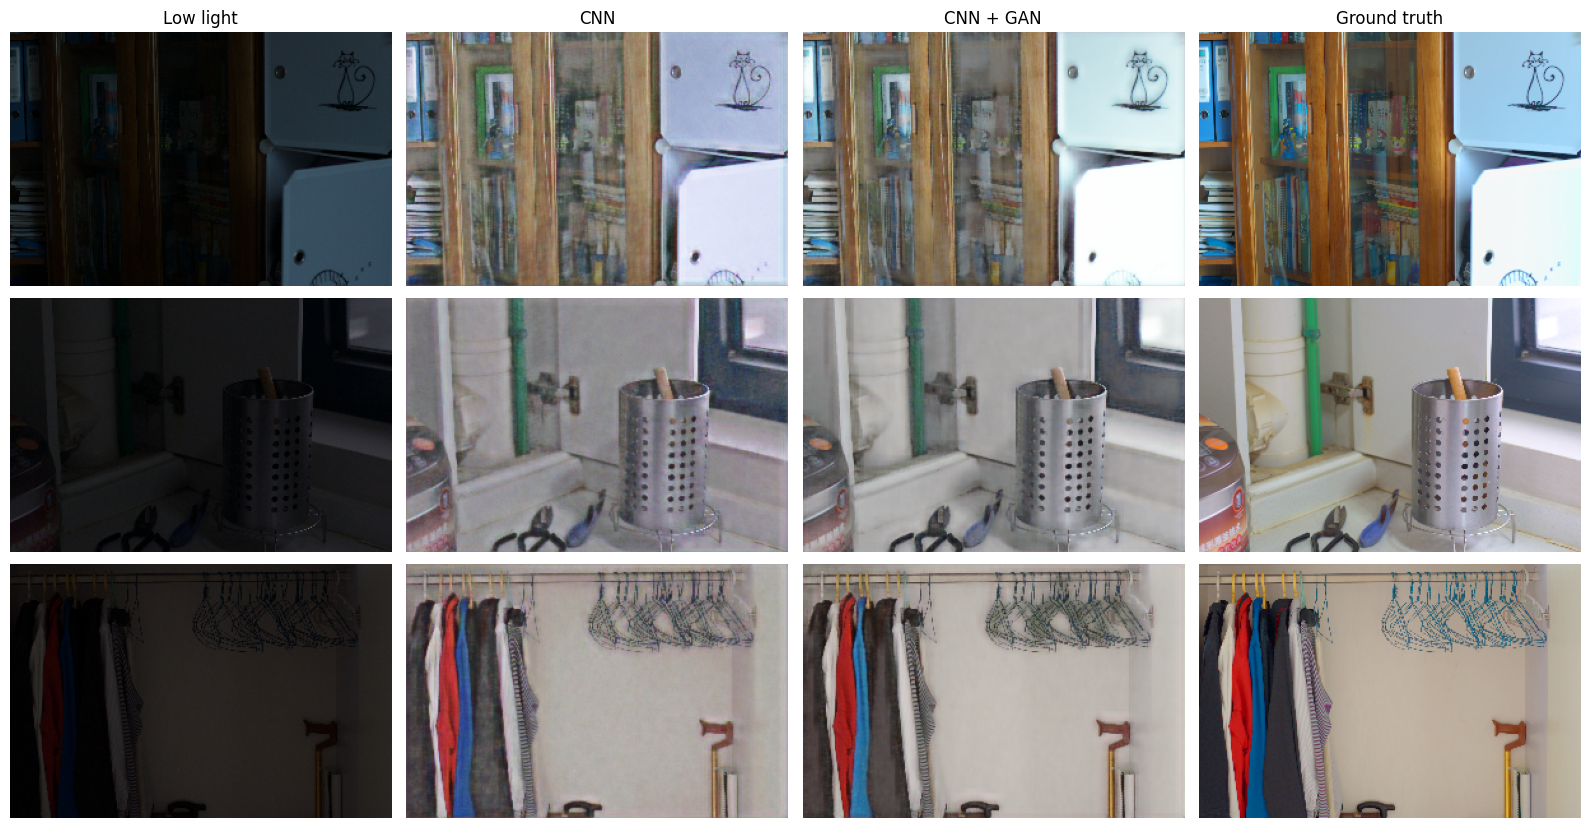

In [ ]:
# Final comparison on the 15 held-out test images: input vs CNN vs CNN + GAN
cnn_model = load_model(CNN_BEST_PATH, compile=False)
gan_model = load_model(GAN_BEST_PATH, compile=False)
cnn_pred = cnn_model.predict(test_low_light_images, batch_size=8, verbose=0)
gan_pred = gan_model.predict(test_low_light_images, batch_size=8, verbose=0)

test_scores = {'input':   score(test_normal_light_images, test_low_light_images),
               'cnn':     score(test_normal_light_images, cnn_pred),
               'cnn_gan': score(test_normal_light_images, gan_pred)}
print('Input (no model):', test_scores['input'])
print('CNN             :', test_scores['cnn'])
print('CNN + GAN       :', test_scores['cnn_gan'])

# Saved so a final summary can compare all models side by side
with open(os.path.join(SAVE_DIR, f'{MODEL_NAME}_gan_test.json'), 'w') as f:
    json.dump(test_scores, f, indent=2)

show_results([test_low_light_images, cnn_pred, gan_pred, test_normal_light_images],
             ['Low light', 'CNN', 'CNN + GAN', 'Ground truth'])